# 4D KAN Convergence Spot Checks

Single-model runs of the 4D KAN sweep at `n = 200, 400, 600`, to look at the actual training history behind the sweep's error-vs-samples plot. In that plot the KAN error stays well above the MLP and Kriging errors until around n=500 and varies a lot between seeds.

Every run uses the exact settings from the 4D cell in `SingleFidelityComparison_KAN.ipynb`: `width=[4, 6, 6, 1]`, `grid=[3, 5]`, `n_iter=400` per grid stage, LBFGS with `lr=1.0`, `lamb=0`, scaled inputs and outputs. The sweep used `seeds=2`, so each `n` is run with both seed 0 and seed 1, which use the same training points as the sweep.

The loss curves are pykan's RMSE on the **scaled** (z-scored) outputs, not original units; `model_error` printed by each run is in original units. The dashed line marks the `grid 3 -> 5` refinement at step 400.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from examples import single_fidelity_kan_helpers as kan_helpers

In [2]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kan_helpers.create_test_points(my_function, n=1000)

# Same settings as the 4D sweep in SingleFidelityComparison_KAN.ipynb
sweep_settings = dict(
    hidden_layers=[6, 6],
    grid=[3, 5],
    spline_order=3,
    opt="LBFGS",
    n_iter=400,
    lr=1.0,
    lamb=0.0,
)
models = {}


def run_spot_check(n, seed):
    model, error, train_time, _ = kan_helpers.generate_kan_model(
        name=key, func=my_function, n=n, seed=seed, X_test=X_test, y_test=y_test, **sweep_settings
    )
    models[(n, seed)] = model
    ax = model.plot_fit_error(f"4D KAN Fit Error n={n}, seed={seed}")
    ax.axvline(sweep_settings["n_iter"], color="gray", linestyle="--", label="grid 3 -> 5")
    ax.set_yscale("log")
    ax.legend()
    kan_helpers.save_plot(ax, f"4D_spotcheck_n{n}_seed{seed}_grid3-5_width4-6-6-1")
    plt.show()
    kan_helpers.print_convergence_report(f"4D n={n} seed={seed}", model.train_losses, model.test_losses)
    return model

### n = 200

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 7.41e-04 | test_loss: 5.29e-02 | reg: 3.09e+01 | : 100%|█| 400/400 [07:01<00:00,  1.05


saving model version 0.1
saving model version 0.2


| train_loss: 2.05e-04 | test_loss: 4.60e-02 | reg: 3.09e+01 | : 100%|█| 400/400 [02:47<00:00,  2.39


saving model version 0.3
Run 4D :: seed 0 :: points 200 :: error 4.966898441314697 :: train_time 590.4728308999911 :: evaluation_time 0.06030019999889191


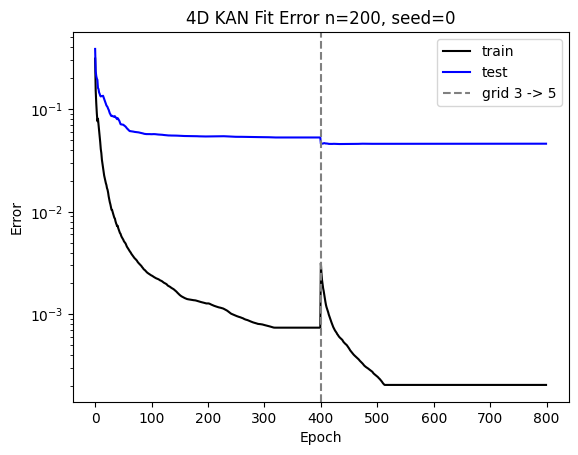

4D n=200 seed=0: train=0.0002052 test=0.04603 gap=224.36x | best_test=0.04565 (at 56% of training) degradation=1.01x -> WATCH


In [3]:
model_n200_seed0 = run_spot_check(n=200, seed=0)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 6.57e-04 | test_loss: 5.26e-02 | reg: 3.09e+01 | : 100%|█| 400/400 [04:53<00:00,  1.36


saving model version 0.1
saving model version 0.2


| train_loss: 8.51e-05 | test_loss: 5.87e-02 | reg: 3.10e+01 | : 100%|█| 400/400 [03:44<00:00,  1.78


saving model version 0.3
Run 4D :: seed 1 :: points 200 :: error 6.372264385223389 :: train_time 518.159055199998 :: evaluation_time 0.056015099995420314


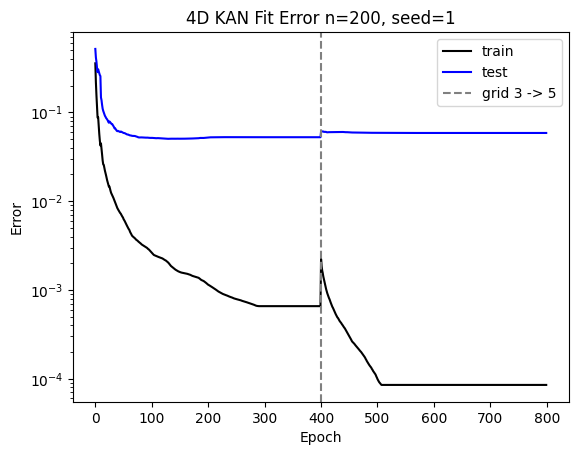

4D n=200 seed=1: train=8.511e-05 test=0.05873 gap=690.04x | best_test=0.05041 (at 18% of training) degradation=1.17x -> WATCH


In [4]:
model_n200_seed1 = run_spot_check(n=200, seed=1)

### n = 400

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 7.05e-04 | test_loss: 1.88e-03 | reg: 2.83e+01 | : 100%|█| 400/400 [05:31<00:00,  1.21


saving model version 0.1
saving model version 0.2


| train_loss: 3.33e-04 | test_loss: 1.46e-03 | reg: 2.78e+01 | : 100%|█| 400/400 [02:44<00:00,  2.43


saving model version 0.3
Run 4D :: seed 0 :: points 400 :: error 0.16223591566085815 :: train_time 497.05530290000024 :: evaluation_time 0.05906609998783097


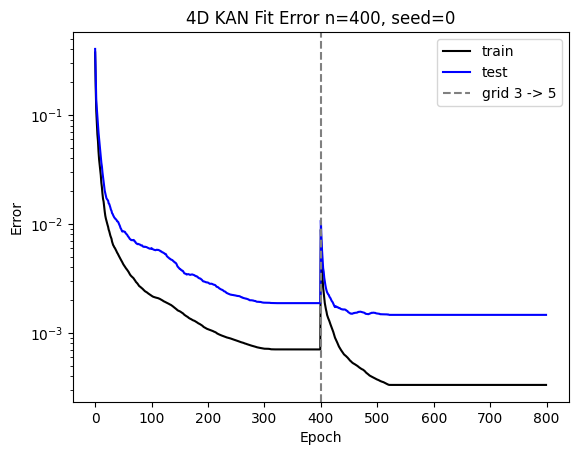

4D n=400 seed=0: train=0.000333 test=0.001463 gap=4.39x | best_test=0.001463 (at 65% of training) degradation=1.00x -> OK


In [5]:
model_n400_seed0 = run_spot_check(n=400, seed=0)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 6.99e-04 | test_loss: 4.69e-03 | reg: 2.81e+01 | : 100%|█| 400/400 [04:56<00:00,  1.35


saving model version 0.1
saving model version 0.2


| train_loss: 2.84e-04 | test_loss: 4.35e-03 | reg: 2.81e+01 | : 100%|█| 400/400 [02:45<00:00,  2.42


saving model version 0.3
Run 4D :: seed 1 :: points 400 :: error 0.4605555236339569 :: train_time 463.01951509999344 :: evaluation_time 0.049278899998171255


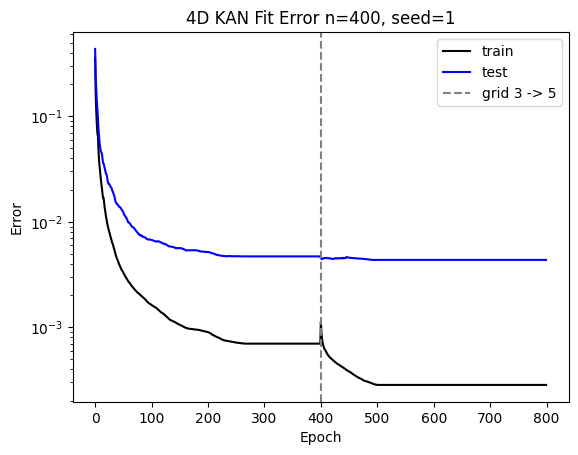

4D n=400 seed=1: train=0.0002839 test=0.004349 gap=15.32x | best_test=0.004342 (at 62% of training) degradation=1.00x -> WATCH


In [6]:
model_n400_seed1 = run_spot_check(n=400, seed=1)

### n = 600

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 6.65e-04 | test_loss: 1.63e-03 | reg: 2.91e+01 | : 100%|█| 400/400 [06:00<00:00,  1.11


saving model version 0.1
saving model version 0.2


| train_loss: 3.68e-04 | test_loss: 1.13e-03 | reg: 2.91e+01 | : 100%|█| 400/400 [02:18<00:00,  2.89


saving model version 0.3
Run 4D :: seed 0 :: points 600 :: error 0.12109584361314774 :: train_time 499.4318154999928 :: evaluation_time 0.09311989998968784


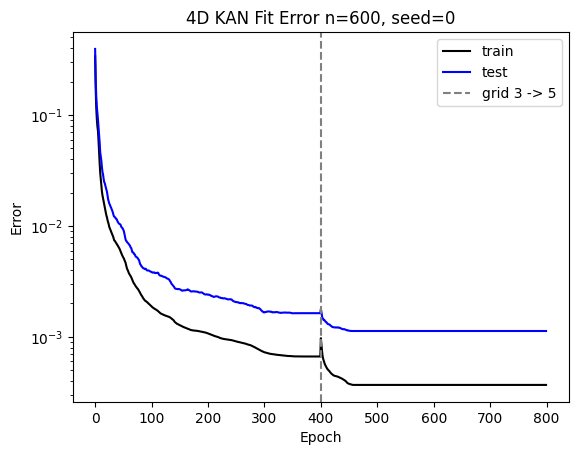

4D n=600 seed=0: train=0.0003684 test=0.001129 gap=3.06x | best_test=0.001128 (at 57% of training) degradation=1.00x -> OK


In [7]:
model_n600_seed0 = run_spot_check(n=600, seed=0)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.06e-03 | test_loss: 2.79e-03 | reg: 2.69e+01 | : 100%|█| 400/400 [11:24<00:00,  1.71


saving model version 0.1
saving model version 0.2


| train_loss: 3.64e-04 | test_loss: 1.80e-02 | reg: 2.60e+01 | : 100%|█| 400/400 [10:17<00:00,  1.54


saving model version 0.3
Run 4D :: seed 1 :: points 600 :: error 1.8226573467254639 :: train_time 1303.2074914999976 :: evaluation_time 0.14632679999340326


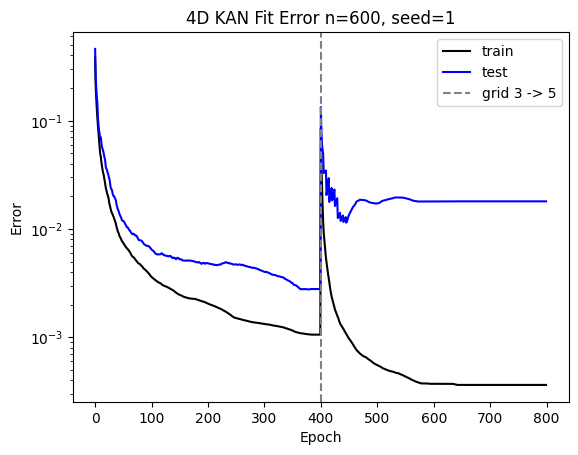

4D n=600 seed=1: train=0.0003639 test=0.01798 gap=49.39x | best_test=0.002768 (at 47% of training) degradation=6.49x -> OVERFIT


In [8]:
model_n600_seed1 = run_spot_check(n=600, seed=1)

### Summary

In [9]:
for (n, seed), model in sorted(models.items()):
    kan_helpers.print_convergence_report(f"4D n={n} seed={seed}", model.train_losses, model.test_losses)

4D n=200 seed=0: train=0.0002052 test=0.04603 gap=224.36x | best_test=0.04565 (at 56% of training) degradation=1.01x -> WATCH
4D n=200 seed=1: train=8.511e-05 test=0.05873 gap=690.04x | best_test=0.05041 (at 18% of training) degradation=1.17x -> WATCH
4D n=400 seed=0: train=0.000333 test=0.001463 gap=4.39x | best_test=0.001463 (at 65% of training) degradation=1.00x -> OK
4D n=400 seed=1: train=0.0002839 test=0.004349 gap=15.32x | best_test=0.004342 (at 62% of training) degradation=1.00x -> WATCH
4D n=600 seed=0: train=0.0003684 test=0.001129 gap=3.06x | best_test=0.001128 (at 57% of training) degradation=1.00x -> OK
4D n=600 seed=1: train=0.0003639 test=0.01798 gap=49.39x | best_test=0.002768 (at 47% of training) degradation=6.49x -> OVERFIT
